one slice: torch.Size([1, 224, 224])
as a batch: torch.Size([1, 1, 224, 224])
feature map: torch.Size([1, 1, 224, 224])


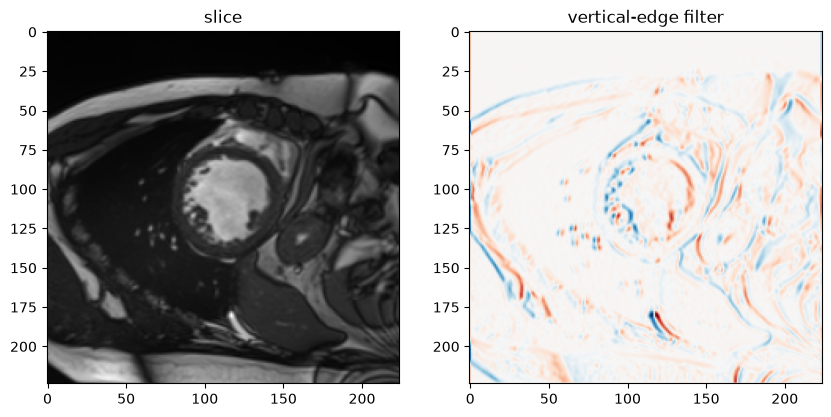

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from cardioseg.data.dataset import ACDCSliceDataset

ds = ACDCSliceDataset("../data/acdc/training", ["patient001"])
image, mask = ds[5]
print("one slice:", image.shape)

batch = image.unsqueeze(0)  # conv2d wants a batch: (batch, channels, height, width)
print("as a batch:", batch.shape)

edge = torch.tensor([[-1.0, 0.0, 1.0],
                     [-2.0, 0.0, 2.0],
                     [-1.0, 0.0, 1.0]]).reshape(1, 1, 3, 3)
edges = F.conv2d(batch, edge, padding=1)
print("feature map:", edges.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image[0], cmap="gray"); axes[0].set_title("slice")
axes[1].imshow(edges[0, 0], cmap="RdBu"); axes[1].set_title("vertical-edge filter")
plt.show()

In [2]:
conv = torch.nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
features = conv(batch)
print("after 32 filters:", features.shape)

for level in range(4):
    features = F.max_pool2d(features, 2)
    print(f"after pooling {level + 1}:", features.shape)

after 32 filters: torch.Size([1, 32, 224, 224])
after pooling 1: torch.Size([1, 32, 112, 112])
after pooling 2: torch.Size([1, 32, 56, 56])
after pooling 3: torch.Size([1, 32, 28, 28])
after pooling 4: torch.Size([1, 32, 14, 14])


In [3]:
from cardioseg.models.unet import UNet

model = UNet()
x = torch.randn(1, 1, 224, 224)
with torch.no_grad():  # just looking, not training
    e1 = model.enc1(x)
    e2 = model.enc2(model.pool(e1))
    e3 = model.enc3(model.pool(e2))
    e4 = model.enc4(model.pool(e3))
    b = model.bottom(model.pool(e4))
    for name, t in [("enc1", e1), ("enc2", e2), ("enc3", e3), ("enc4", e4), ("bottom", b)]:
        print(f"{name:8}", tuple(t.shape))

    up = model.up4(b)
    print("up4     ", tuple(up.shape))
    print("+ skip  ", tuple(torch.cat([up, e4], dim=1).shape))

    scores = model(x)
    print("output  ", tuple(scores.shape))
    print("mask    ", tuple(scores.argmax(dim=1).shape))
    print("one pixel's 4 scores:", scores[0, :, 100, 100].tolist())

print(f"learnable numbers: {sum(p.numel() for p in model.parameters()):,}")

enc1     (1, 32, 224, 224)
enc2     (1, 64, 112, 112)
enc3     (1, 128, 56, 56)
enc4     (1, 256, 28, 28)
bottom   (1, 512, 14, 14)
up4      (1, 256, 28, 28)
+ skip   (1, 512, 28, 28)
output   (1, 4, 224, 224)
mask     (1, 224, 224)
one pixel's 4 scores: [-0.13644908368587494, -0.6302582621574402, 0.1624196320772171, 0.1087154820561409]
learnable numbers: 7,762,564
